# GEOL415 Lab 11: k-Nearest Neighbor Classification

Welcome back to lab. This week we'll be covering a new topic not yet seen in lecture. Unlike last week, however, I am prepared for this reality.

This week we will learn about the k-Nearest Neighbors algorithm. This can be used for a variety of learning tasks; we will focus specifically on classification this week. The learning objectives are as follows:

- Gain an understanding of k-NN, the distance metrics used to determine nearest neighbors, and how k-NN assigns class membership
- Train a k-NN classification model on a small fire dataset detailing Algerian wildfires in the year 2012.
- Use statistical metrics we've seen before to assess and visualize k-NN results.

# 0 Startup

At this point, I trust everyone is working within their `geol415` conda environment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# for k-NN stuff
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.model_selection import train_test_split

# 1 Load dataset

We'll be using a wildfire dataset from [the UCI machine learning repository](https://archive.ics.uci.edu/dataset/547/algerian+forest+fires+dataset). These data detail meteorological and other fire metrics relating to wildfire (or not) occurrences in Algeria in 2012. The original dataset is grouped according to two regions these data were recorded in. For the sake of this lab, these have been glommed into a single CSV.

The non-temporal features are described as follows:

**Weather Data Observations** 

2. Temp : temperature noon (temperature max)  in Celsius degrees: 22 to 42
3. RH : Relative Humidity in %: 21 to 90 
4. Ws :Wind speed in km/h: 6 to 29 
5. Rain: total day in mm: 0 to 16.8

**Fire Weather Index Components**

6. Fine Fuel Moisture Code (FFMC) index from the FWI system: 28.6 to 92.5 
7. Duff Moisture Code (DMC) index from the FWI system: 1.1 to 65.9 
8. Drought Code (DC) index from the FWI system:  7 to 220.4
9. Initial Spread Index (ISI) index from the FWI system: 0 to 18.5 
10. Buildup Index (BUI) index from the FWI system: 1.1 to 68
11. Fire Weather Index (FWI) Index: 0 to 31.1
12. Classes: two classes, namely  **Fire** and **not Fire**

Let's load the data below:

In [2]:
df = pd.read_csv('../Data/algerian_forest_fires_cleaned.csv')

In [3]:
df.isna().sum() # NaN check. We are in the clear!

day            0
month          0
year           0
Temperature    0
RH             0
Ws             0
Rain           0
FFMC           0
DMC            0
DC             0
ISI            0
BUI            0
FWI            0
Classes        0
dtype: int64

# 2 Feature visualization/exploration

Let's plot how the distribution of fire vs not fire shows up within each variable here. We will not look at day, month, or year, as it is all from 2012 for starters, and it will be more interesting to classify based on physical properties rather than temporal.

## 2.1 Plot each feature distribution by fire/no fire

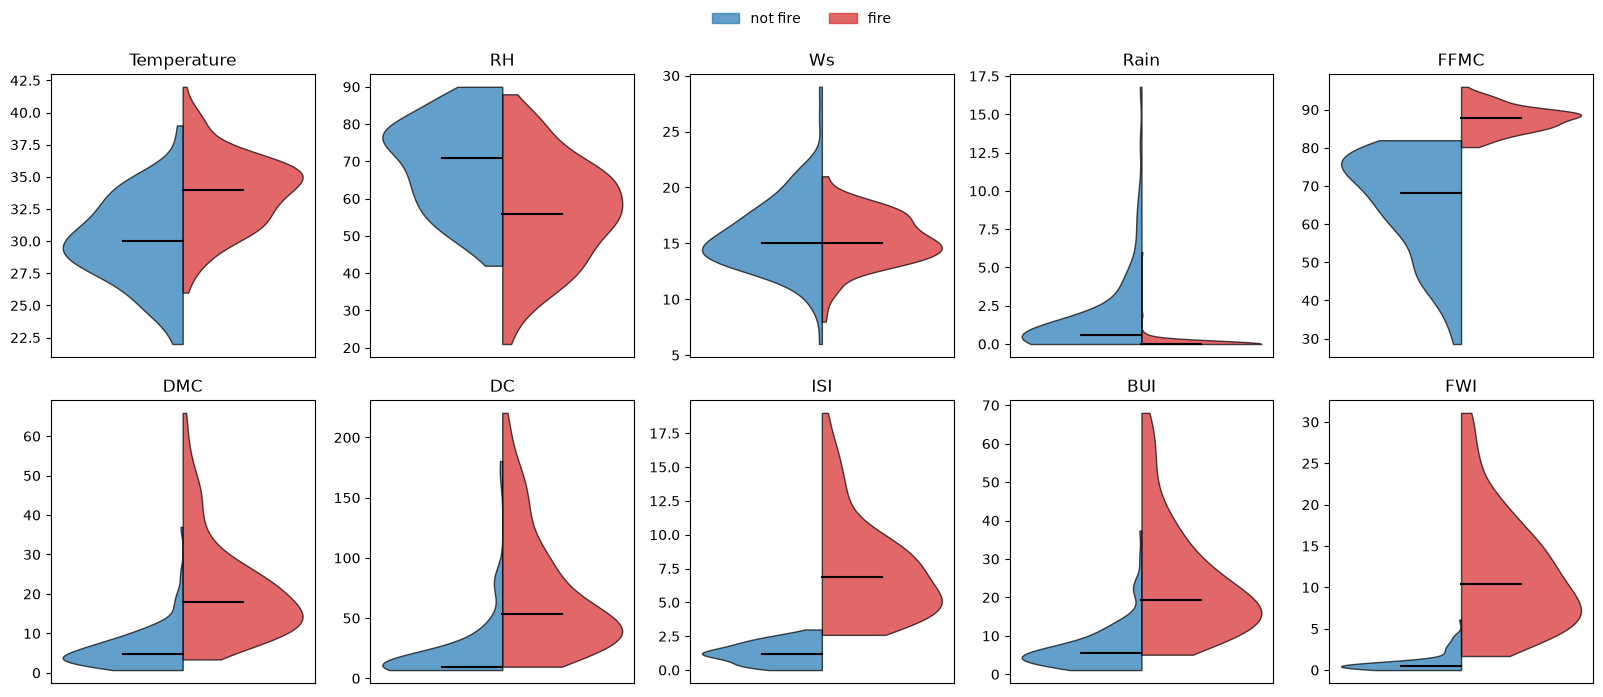

In [4]:
from matplotlib.patches import Patch


features = ["Temperature", "RH", "Ws", "Rain", "FFMC", "DMC", "DC", "ISI", "BUI", "FWI"]


# is_nofire = df["Classes"].str.contains("not")
is_nofire = df['Classes'] == 'not fire'

colors = {"not fire": "tab:blue", "fire": "tab:red"}

# housekeeping plotting stuff. I wouldn't worry about this
fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for ax, feat in zip(axes.flat, features):
    nofire = df.loc[is_nofire, feat].dropna()
    fire = df.loc[~is_nofire, feat].dropna()

    for data, side, key in [(nofire, "low", "not fire"), (fire, "high", "fire")]:
        v = ax.violinplot(data, positions=[0], side=side, widths=0.9,
                          showmedians=True, showextrema=False)
        for body in v["bodies"]:
            body.set_facecolor(colors[key])
            body.set_edgecolor("black")
            body.set_alpha(0.7)
        v["cmedians"].set_color("black")

    ax.set_title(feat)
    ax.set_xticks([])

fig.legend(handles=[Patch(color=c, label=k, alpha=0.7) for k, c in colors.items()],
           loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.95])

**Question:** Which input features display the most striking difference between data rows corresponding to fires vs. not fires? Which one(s) are most similar? At first glance, which feature(s) might you care less about for predicting fire vs no fire, if any?

*Answer*: FFMC, ISI, and FWI show the clearest differences, with higher values for fire observations. Wind speed (Ws) has the most similar distributions, so it seems less useful for predicting fires at first glance.

## 2.2 How much of the dataset are actual fire events?

**Question**: in the cell below, compute the answer to this questions. If we were to pick a silly model that always predicted **fire**, how right would we be on this dataset?

In [5]:
num_total_data = df.shape[0]

#count how many rows are labeled "not fire"
# Hint: use .str.contains("not") (or == "not fire") on df['Classes'], then .sum()
num_not_fire = df['Classes'].str.contains('not').sum()


#print the percentage of fire and not fire rows (formatted to 2 decimals)
# Hint: fire % = 1 - (num_not_fire / num_total_data), times 100
pct_not_fire = (num_not_fire / num_total_data) * 100
pct_fire = (1 - (num_not_fire / num_total_data)) * 100

print(f"Fire: {pct_fire:.2f}%")
print(f"Not Fire: {pct_not_fire:.2f}%")

Fire: 56.56%
Not Fire: 43.44%


*Answer*: 56.56%

# 3 k-Nearest Neighbors

k-Nearest Neighbors (k-NN) is a supervised machine learning method that can be used for both classification and regression tasks alike. Today, we'll be using it for classification purposes, but this can just as well be used to predict continuous data values. 

In the context of classification, k-NN assigns a class label to a data point based on data it has already been exposed to (i.e. the training data). These data have known labels, and when the k-NN classifier sees a new data point, it uses the **k** data points **nearest** the test point to essentially take a vote on what class to assign it. Here, **k** is a hyperparameter chosen by us, the environmental data scientists. A convention I learned, particularly in the case of binary classification, is to make k an odd number, so there's always a tie-breaking data point in the mix.

k-NN can take a variety of different distance metrics to compute how near a point's neighbors are. Today, we'll use the classic Euclidean distance, also known as the L2 norm, also known as the hypotenuse of a right triangle (in the 2-D) case. In 2-D, this looks like 

$$D_{L2} = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$$

In the N-dimensional case (in the case of our full fire dataset, N = 10):

$$D(q,p) = \sqrt{\sum_{i=1}^{n} (q_i - p_i)^2}$$

Here is a visual of what k-NN does in 2-dimensional space. Here, we see two radii based on how many neighbors we want input from.

![Image of knn](https://miro.medium.com/v2/resize:fit:640/format:webp/0*itLUNKOYfZOGZqRX.jpg)

k-NN is relatively lightweight computationally, as all it's doing is taking vector norms between points in space and aggregating class information. Let's see this in action below.

## 3.1 Data prep

First, split your data into inputs and targets. We've done this before with other ML models. Then, we will split our data into train and test sets.

In [6]:
# first, separate out your predictors and your targets
# remember, THESE are our final predictors
features = ["Temperature", "RH", "Ws", "Rain", "FFMC", "DMC", "DC", "ISI", "BUI", "FWI"]

# TODO: X should be the feature columns of df; y should be the 'Classes' column
X, y = df[features], df['Classes']

# THEN, we train/test split
# TODO: call train_test_split with a 70/30 split (test_size = .3), random_state=42, and shuffle on
# Hint: it returns X_train, X_test, y_train, y_test in that order
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, shuffle=True)

In [7]:
def minmax(df, ref):
    """Min-max scale df using the min/max of ref (pass the TRAIN set as ref).
    Args:
    df: dataframe to scale
    ref: reference (i.e. TRAIN) dataframe to use for the min and max values. NOTE: if df = Train data, then df and ref are the same!
    """
    # TODO: return (df - min) / (max - min), where min and max are the
    # column-wise min and max of `ref` (NOT of df). Think about why!
    col_min = ref.min()
    col_max = ref.max()
    return (df - col_min) / (col_max - col_min)

Last week we z-scored. This week we will min-max normalize so that each feature exists between 0 and 1. k-NN relies on raw distances, so without scaling, features with large numeric ranges (e.g. `DC`, up to ~220) would dominate the distance calculation over features with small ranges (e.g. `Rain`, `ISI`).

Notice that `minmax` takes a `ref` argument: we always scale using the **training** set's min and max, and apply those same numbers to the test set.

In [8]:
X_train_scaled, X_test_scaled = minmax(X_train, X_train), minmax(X_test, X_train)

Note: We split our data first, and then normalized via min-max normalization. This is important.

**Question**: Why is it important to normalize/scale our data after we split our dataset, rather than before? What's the harm in doing so?

*Answer*: Scaling before splitting would let information from the test set influence data preparation. This is actually data leakage and can make model performance look better than it really is.

## 3.2 Implement kNN Classifier

`sklearn` makes it immensely easy to do this. We'll use k=5 neighbors in this example. Feel free to play around with this number.

In [9]:
# TODO: create a KNeighborsClassifier with 5 neighbors
kNN = KNeighborsClassifier(n_neighbors=5)

# TODO: fit the model on the SCALED training data (X_train_scaled) and y_train
kNN.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['fire','not fire']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## 3.3 Predict the class of each `X_test` data point using the trained k-NN classifier.

Here, "training" = "the k-NN classifier memorized every train data point and is calculating distances between them and the test data." 

In [10]:
# TODO: predict classes for the SCALED test data and store them in test_preds
test_preds = kNN.predict(X_test_scaled)
test_preds[:10] # first 10 predictions

array(['fire', 'fire', 'fire', 'not fire', 'fire', 'not fire', 'fire',
       'not fire', 'not fire', 'not fire'], dtype=object)

# 4 Visualizing/analyzing results

Now that we have a trained model, we can analyze how good (or not) this performance is. Since we're doing classification, you should be thinking about accuracy, precision, recall, f1 score, things of that nature. We've also seen how we might visualize these metrics with a confusion matrix. Let's import these functions below and see what our results look like.

## 4.1 Error Metrics

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score, ConfusionMatrixDisplay

In [12]:
# TODO: compute precision, recall, and f1 for the "fire" class
# Hint: precision_score(y_true, y_pred, pos_label="fire"), and similarly for the others
# HINT 2: pos_label="fire" is important here, as we never changed our categories to 0s and 1s
prec = precision_score(y_test, test_preds, pos_label="fire")
rec = recall_score(y_test, test_preds, pos_label="fire")
f1 = f1_score(y_test, test_preds, pos_label="fire")
print(f'Our k-NN model has a precision score of {prec:.02f}, recall score of {rec:.02f}, and f1 score of {f1:.02f}')

Our k-NN model has a precision score of 1.00, recall score of 0.94, and f1 score of 0.97


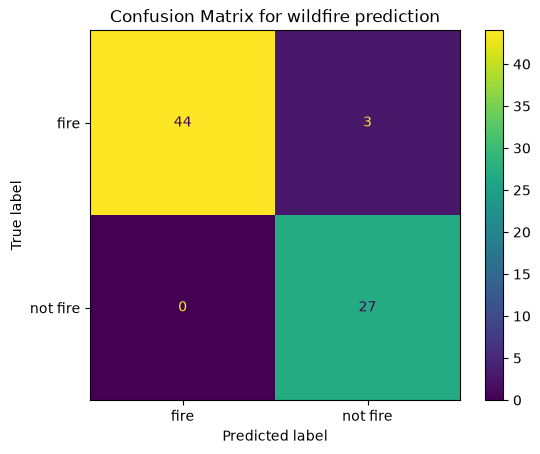

In [13]:
#confusion matrix
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, 
    test_preds, 
    labels=["fire", "not fire"],
    cmap=plt.cm.viridis
)

plt.title("Confusion Matrix for wildfire prediction")
plt.show()

Here, the colorbar numbers refer to the counts of correctly (or not) classified test cases.

**Question**: Pick any one of the above metrics used to numerically assess how good our classifier is. Explain **in words** (your own, preferably, i.e. not some guy named Claude's) what the metric is and how this metric explains model performance.

*Answer*: Recall measures how many actual fires the model correctly identifies. Here, recall is about 94%, meaning the model correctly identified 44 of the 47 fire observations and missed 3.

## 4.2 Visualizing nearest neighbors in lower-dimensional space

Let's try and create a similar plot to the image I showed you above. For the sake of illustration, let's look at two features from our dataset, `Temperature` and `RH`. We can plot a test point or two and see how it gets it's class predicted. 

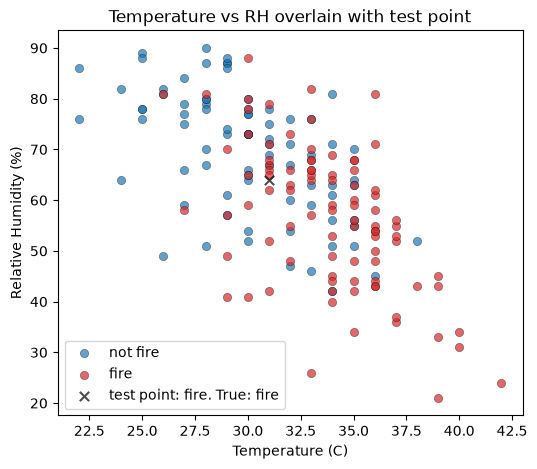

In [14]:
train_nofire = y_train.str.contains("not")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X_train.loc[train_nofire, "Temperature"], X_train.loc[train_nofire, "RH"],
           c="tab:blue", label="not fire", alpha=0.7, edgecolor="k", linewidth=0.3)
ax.scatter(X_train.loc[~train_nofire, "Temperature"], X_train.loc[~train_nofire, "RH"],
           c="tab:red", label="fire", alpha=0.7, edgecolor="k", linewidth=0.3)

#example (plotted in original units; the model itself uses the scaled features)
test_point = X_test.iloc[:1,:][['Temperature', 'RH']]
predicted_label = kNN.predict(X_test_scaled.iloc[:1,:])[0]

ax.scatter(test_point['Temperature'], test_point['RH'], 
           color='black', alpha=0.7, s=45, marker='x', label=f'test point: {predicted_label}. True: {y_test.iloc[0]}')

ax.set_xlabel("Temperature (C)")
ax.set_ylabel("Relative Humidity (%)")
plt.title('Temperature vs RH overlain with test point')
ax.legend()
plt.show()

We see the test point is (correctly) classified as fire. Let's see that in compressed space. Compute the L2 norm of the test point against all train data points, and select the 5 closest data points to it. 

In [15]:
# Get distance from the test point to all train points (in full, scaled feature space)
Xt_copy = X_train_scaled.copy() # copy this and add column 'L2' to it
test_point_x = X_test_scaled.iloc[:1,:] # full (scaled) values

# TODO: compute the Euclidean (L2) distance between test_point_x and EVERY row of Xt_copy
# Hint: np.linalg.norm(<train values> - <test point values>, axis=1) -- see the formula above
Xt_copy['L2'] = np.linalg.norm(Xt_copy.values - test_point_x.values, axis=1)
Xt_copy

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,L2
234,0.65,0.188406,0.55,0.000000,0.943620,0.351227,0.423419,0.726316,0.423019,0.694534,0.824938
227,0.30,0.869565,0.45,0.000000,0.830861,0.182515,0.162061,0.226316,0.197309,0.183280,0.335001
180,0.60,0.550725,0.50,0.000000,0.882789,0.288344,0.188759,0.389474,0.275037,0.350482,0.241091
5,0.45,0.666667,0.40,0.000000,0.801187,0.078221,0.071663,0.163158,0.088191,0.080386,0.381970
56,0.70,0.391304,0.35,0.000000,0.915430,0.329755,0.475878,0.457895,0.423019,0.491961,0.538235
...,...,...,...,...,...,...,...,...,...,...,...
106,0.10,0.884058,0.45,0.023810,0.241840,0.003067,0.001874,0.010526,0.004484,0.000000,0.952862
14,0.30,0.855072,0.55,0.184524,0.308605,0.035276,0.002342,0.021053,0.028401,0.003215,0.852771
92,0.15,0.797101,0.55,0.428571,0.258160,0.009202,0.002810,0.010526,0.010463,0.003215,1.001547
179,0.55,0.521739,0.50,0.000000,0.873887,0.230061,0.143794,0.352632,0.218236,0.289389,0.207784


In [16]:
# now, get the 5 closest points by L2 distance
# TODO: sort Xt_copy by 'L2' (smallest first), keep the first 5 rows and every column EXCEPT L2,
# and save the resulting row labels (.index) as nearest_idx
# Hint: .sort_values('L2').iloc[:5, :-1].index
nearest_idx = Xt_copy.sort_values('L2').iloc[:5, :-1].index

# look the same rows up in the unscaled data so we can plot them in original units
five_nearest = X_train.loc[nearest_idx]
five_nearest

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI
23,32,66,17,0.0,85.9,11.2,55.8,5.6,14.9,7.5
239,30,65,14,0.0,85.4,16.0,44.5,4.5,16.9,6.5
47,31,68,14,0.0,85.4,12.1,43.1,4.6,14.2,6.0
35,32,63,14,0.0,87.0,10.9,37.0,5.6,12.5,6.8
50,33,70,17,0.0,85.4,18.5,71.5,5.2,22.4,8.8


Let's replot with the five closest points (in 10-D space) highlighted to see which points made that decision

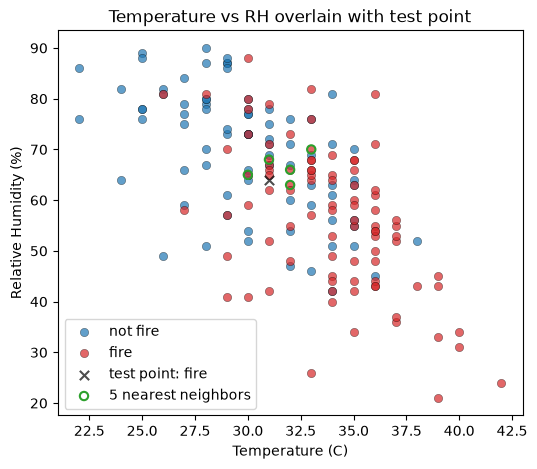

In [17]:
# plot these with their own color
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X_train.loc[train_nofire, "Temperature"], X_train.loc[train_nofire, "RH"],
           c="tab:blue", label="not fire", alpha=0.7, edgecolor="k", linewidth=0.3)
ax.scatter(X_train.loc[~train_nofire, "Temperature"], X_train.loc[~train_nofire, "RH"],
           c="tab:red", label="fire", alpha=0.7, edgecolor="k", linewidth=0.3)

#example
test_point = X_test.iloc[:1,:][['Temperature', 'RH']]
predicted_label = kNN.predict(X_test_scaled.iloc[:1,:])[0]

ax.scatter(test_point['Temperature'], test_point['RH'], 
           color='black', alpha=0.7, s=45, marker='x', label=f'test point: {predicted_label}')

ax.scatter(five_nearest['Temperature'], five_nearest['RH'], 
           facecolors='none', edgecolors='tab:green', linewidths=1.5, alpha=1., label='5 nearest neighbors')

ax.set_xlabel("Temperature (C)")
ax.set_ylabel("Relative Humidity (%)")
plt.title('Temperature vs RH overlain with test point')
ax.legend()
plt.show()

**Question**: These points do not look all that close to X. At least, not in Temperature/RH space. Note we calculated distance with all 10 (scaled) features of our data. Does that explain why x's nearest neighbors might show up wonky on a 2-D plot?

*Answer*: Yes. The model finds neighbors using all 10 scaled features, but the plot shows only temperature and relative humidity. Points can be close across all features without appearing closest in this two-feature plot.

## Mini-Evals (please fill out!!!)

1. Please rate 1-5 how this lab was for you. 1 := this was too difficult, 5 := I could do this in my sleep.

*Answer*: 3

2. What is something you wished I covered in this lab? 

*Answer*: N/A

# Lab submission


Please `Restart` and `Run All` on this notebook and submit this lab when you are done!